In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/jeandamourniyonsaba/country-schools-1/Country Schools (1).csv


In [2]:
import pandas as pd

hf = pd.read_csv("/kaggle/input/datasets/jeandamourniyonsaba/country-schools-1/Country Schools (1).csv")




In [3]:
hf.head()

,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
0,TURKANA,358.0,37.0,321.0,10.34%,3744.0,74.0,1
1,HOMA BAY,875.0,552.0,323.0,63.09%,22982.0,1104.0,2
2,WEST POKOT,498.0,242.0,256.0,48.59%,15114.0,484.0,3
3,KITUI,1238.0,1200.0,38.0,96.93%,42162.0,2400.0,4
4,TANA RIVER,159.0,143.0,16.0,89.94%,7415.0,286.0,5


In [4]:
hf.tail()

,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
45,EMBU,381.0,248.0,133.0,65.09%,8438.0,496.0,46
46,SAMBURU,146.0,49.0,97.0,33.56%,2891.0,98.0,47
47,TOTAL,21729.0,14629.0,7100.0,67.32%,723618.0,29258.0,48
48,NaN,NaN,NaN,NaN,NaN,NaN,NaN,49
49,NaN,NaN,NaN,NaN,NaN,NaN,NaN,50


In [5]:
hf.describe()

,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,InstalledLDDs,InstalledTDDs,FID
count,48.000000,48.000000,48.000000,48.00000,48.000000,50.00000
mean,905.375000,609.541667,295.833333,30150.75000,1219.083333,25.50000
std,3079.865641,2078.968965,1009.291416,102851.94788,4157.937929,14.57738
min,93.000000,8.000000,4.000000,606.00000,16.000000,1.00000
25%,271.750000,161.250000,53.250000,6289.00000,322.500000,13.25000
50%,422.500000,314.500000,130.500000,14165.00000,629.000000,25.50000
75%,637.000000,420.250000,247.750000,23215.00000,840.500000,37.75000
max,21729.000000,14629.000000,7100.000000,723618.00000,29258.000000,50.00000


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42


**Load the CSV fileOn Kaggle, upload the CSV into your notebook using Add Input. The following code searches the Kaggle input directory and also supports running locally. It raises a clear error if the file is missing**


In [7]:
candidates = list(Path("/kaggle/input").rglob("Country Schools (1).csv")) if Path("/kaggle/input").exists() else []
candidates += [Path("Country Schools (1).csv"), Path("/mnt/data/Country Schools (1).csv")]
file_path = next((p for p in candidates if p.is_file()), None)
if file_path is None:
    raise FileNotFoundError("Add Country Schools (1).csv to Kaggle Input before running.")

raw_df = pd.read_csv(file_path)
print("Loaded:", file_path)
print("Original shape:", raw_df.shape)
display(raw_df.head())

Loaded: /kaggle/input/datasets/jeandamourniyonsaba/country-schools-1/Country Schools (1).csv
Original shape: (50, 8)


,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
0,TURKANA,358.0,37.0,321.0,10.34%,3744.0,74.0,1
1,HOMA BAY,875.0,552.0,323.0,63.09%,22982.0,1104.0,2
2,WEST POKOT,498.0,242.0,256.0,48.59%,15114.0,484.0,3
3,KITUI,1238.0,1200.0,38.0,96.93%,42162.0,2400.0,4
4,TANA RIVER,159.0,143.0,16.0,89.94%,7415.0,286.0,5


**Initial data inspection
Identify column types, missing values, duplicate rows, and descriptive statistics. The original dataset contains 50 rows, with two blank county rows, one national TOTAL row, and 47 county records.**

In [8]:
print("Column types:")
print(raw_df.dtypes)
print("\nMissing values by column:")
print(raw_df.isna().sum())
print("\nFully duplicated rows:", raw_df.duplicated().sum())
display(raw_df.describe(include="all"))

Column types:
SNO                       object
TOTALSCHOOLS             float64
TotalSchoolsInstalled    float64
SchoolsPending           float64
PercentageInstalled       object
InstalledLDDs            float64
InstalledTDDs            float64
FID                        int64
dtype: object

Missing values by column:
SNO                      2
TOTALSCHOOLS             2
TotalSchoolsInstalled    2
SchoolsPending           2
PercentageInstalled      2
InstalledLDDs            2
InstalledTDDs            2
FID                      0
dtype: int64

Fully duplicated rows: 0


,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
count,48,48.000000,48.000000,48.000000,48,48.00000,48.000000,50.00000
unique,48,NaN,NaN,NaN,48,NaN,NaN,NaN
top,TURKANA,NaN,NaN,NaN,10.34%,NaN,NaN,NaN
freq,1,NaN,NaN,NaN,1,NaN,NaN,NaN
mean,NaN,905.375000,609.541667,295.833333,NaN,30150.75000,1219.083333,25.50000
std,NaN,3079.865641,2078.968965,1009.291416,NaN,102851.94788,4157.937929,14.57738
min,NaN,93.000000,8.000000,4.000000,NaN,606.00000,16.000000,1.00000
25%,NaN,271.750000,161.250000,53.250000,NaN,6289.00000,322.500000,13.25000
50%,NaN,422.500000,314.500000,130.500000,NaN,14165.00000,629.000000,25.50000
75%,NaN,637.000000,420.250000,247.750000,NaN,23215.00000,840.500000,37.75000


**Data cleaning and validation
Remove blank county rows and the aggregated TOTAL row, convert percentage strings to numbers, ensure numeric values are valid, and check that installed + pending equals all schools. The percentage is stored as a percentage-point value, so 67.32 means 67.32%. Keep the national total for a later cross-check but do not use it for modeling.**

In [9]:
df = raw_df.dropna(subset=["SNO"]).copy()
df["SNO"] = df["SNO"].astype(str).str.strip()
df = df[df["SNO"].str.upper() != "TOTAL"].copy()

numeric_columns = ["TOTALSCHOOLS", "TotalSchoolsInstalled", "SchoolsPending",
                   "InstalledLDDs", "InstalledTDDs"]
for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")
df["PercentageInstalled"] = pd.to_numeric(
    df["PercentageInstalled"].astype(str).str.replace("%", "", regex=False),
    errors="coerce"
)

print("Missing values after type conversion:")
print(df.isna().sum())
df = df.dropna(subset=numeric_columns + ["PercentageInstalled"]).copy()
df = df[(df["TOTALSCHOOLS"] > 0) & (df["TotalSchoolsInstalled"] > 0)].copy()
df = df.drop_duplicates(subset=["SNO"]).reset_index(drop=True)

df["LDDsPerInstalledSchool"] = df["InstalledLDDs"] / df["TotalSchoolsInstalled"]
df["CalculatedPercentage"] = 100 * df["TotalSchoolsInstalled"] / df["TOTALSCHOOLS"]
df["CountDifference"] = df["TOTALSCHOOLS"] - df["TotalSchoolsInstalled"] - df["SchoolsPending"]
df["PercentDifference"] = (df["PercentageInstalled"] - df["CalculatedPercentage"]).abs()

print("Cleaned records:", len(df))
print("School-count inconsistencies:", (df["CountDifference"].abs() > 0.01).sum())
print("Percentage inconsistencies (> 0.02 percentage points):",
      (df["PercentDifference"] > 0.02).sum())
display(df.head())

Missing values after type conversion:
SNO                      0
TOTALSCHOOLS             0
TotalSchoolsInstalled    0
SchoolsPending           0
PercentageInstalled      0
InstalledLDDs            0
InstalledTDDs            0
FID                      0
dtype: int64
Cleaned records: 47
School-count inconsistencies: 0
Percentage inconsistencies (> 0.02 percentage points): 0


,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID,LDDsPerInstalledSchool,CalculatedPercentage,CountDifference,PercentDifference
0,TURKANA,358.0,37.0,321.0,10.34,3744.0,74.0,1,101.189189,10.335196,0.0,0.004804
1,HOMA BAY,875.0,552.0,323.0,63.09,22982.0,1104.0,2,41.634058,63.085714,0.0,0.004286
2,WEST POKOT,498.0,242.0,256.0,48.59,15114.0,484.0,3,62.454545,48.594378,0.0,0.004378
3,KITUI,1238.0,1200.0,38.0,96.93,42162.0,2400.0,4,35.135000,96.930533,0.0,0.000533
4,TANA RIVER,159.0,143.0,16.0,89.94,7415.0,286.0,5,51.853147,89.937107,0.0,0.002893


**Exploratory data analysis
Report the total number of schools, overall weighted completion rate, descriptive statistics, and installation rates by county. The weighted national percentage should be calculated from aggregate counts rather than taking the simple mean of county percentages**

Total schools: 21,729
Schools installed: 14,629
Schools pending: 7,100
Overall completion percentage: 67.32%
Mean of county completion percentages: 63.92%


,TOTALSCHOOLS,PercentageInstalled,LDDsPerInstalledSchool
count,47.00,47.00,47.00
mean,462.32,63.92,53.00
std,254.20,25.85,19.53
min,93.00,4.55,25.73
25%,251.50,50.30,38.24
50%,413.00,65.00,47.74
75%,633.50,84.94,61.45
max,1238.00,96.93,116.22


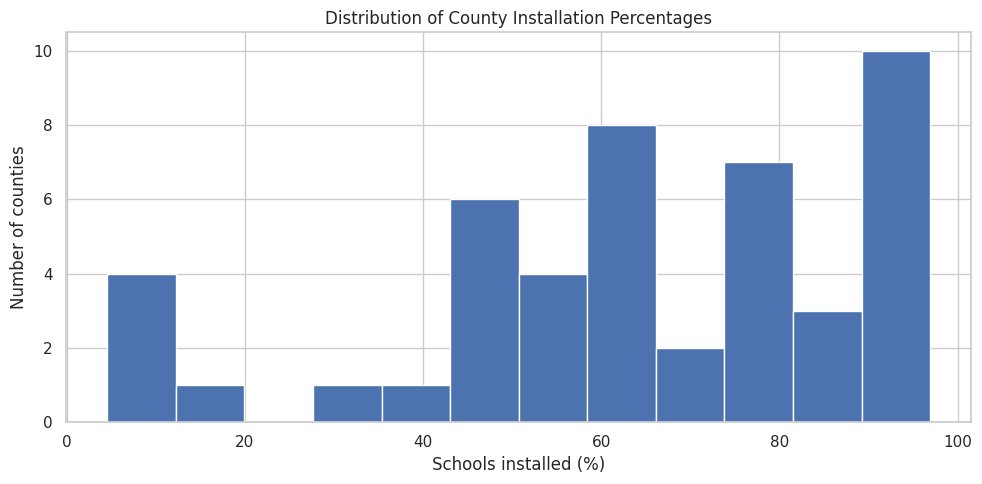

In [10]:
total_schools = df["TOTALSCHOOLS"].sum()
installed = df["TotalSchoolsInstalled"].sum()
pending = df["SchoolsPending"].sum()
weighted_rate = 100 * installed / total_schools

print(f"Total schools: {total_schools:,.0f}")
print(f"Schools installed: {installed:,.0f}")
print(f"Schools pending: {pending:,.0f}")
print(f"Overall completion percentage: {weighted_rate:.2f}%")
print(f"Mean of county completion percentages: {df['PercentageInstalled'].mean():.2f}%")
display(df[["TOTALSCHOOLS", "PercentageInstalled", "LDDsPerInstalledSchool"]].describe().round(2))

plt.figure(figsize=(10, 5))
plt.hist(df["PercentageInstalled"], bins=12, edgecolor="white")
plt.title("Distribution of County Installation Percentages")
plt.xlabel("Schools installed (%)")
plt.ylabel("Number of counties")
plt.tight_layout()
plt.show()

**Select and standardize modeling features
We use three interpretable features:
- TOTALSCHOOLS: county school-system size.
- PercentageInstalled: share of schools with installations.
- LDDsPerInstalledSchool: intensity of LDD installations per installed school.**

In [11]:
features = ["TOTALSCHOOLS", "PercentageInstalled", "LDDsPerInstalledSchool"]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features])
print("Features selected:", features)
print("Standardized matrix shape:", X_scaled.shape)

Features selected: ['TOTALSCHOOLS', 'PercentageInstalled', 'LDDsPerInstalledSchool']
Standardized matrix shape: (47, 3)


**Anomaly detection using Isolation Forest
Isolation Forest isolates unusual observations using random tree partitions. A negative prediction (-1) indicates a flagged anomaly; 1 indicates a typical observation. The chosen contamination=0.10 asks the model to flag approximately 10% of county records, so the number flagged is partly controlled by this parameter. Higher positive anomaly scores below mean greater unusualness.**

In [12]:
detector = IsolationForest(n_estimators=300, contamination=0.10,
                           random_state=RANDOM_STATE)
df["AnomalyFlag"] = detector.fit_predict(X_scaled)
df["AnomalyScore"] = -detector.score_samples(X_scaled)
df["AnomalyLabel"] = np.where(df["AnomalyFlag"] == -1, "Anomaly", "Normal")

anomalies = df[df["AnomalyFlag"] == -1].sort_values("AnomalyScore", ascending=False)
print("Number of anomalous counties:", len(anomalies))
display(anomalies[["SNO"] + features + ["AnomalyScore"]].round(3))

Number of anomalous counties: 5


,SNO,TOTALSCHOOLS,PercentageInstalled,LDDsPerInstalledSchool,AnomalyScore
3,KITUI,1238.0,96.93,35.135,0.653
30,MANDERA,198.0,4.55,116.222,0.651
0,TURKANA,358.0,10.34,101.189,0.632
38,MARSABIT,138.0,5.80,75.750,0.566
36,WAJIR,211.0,5.21,77.727,0.556


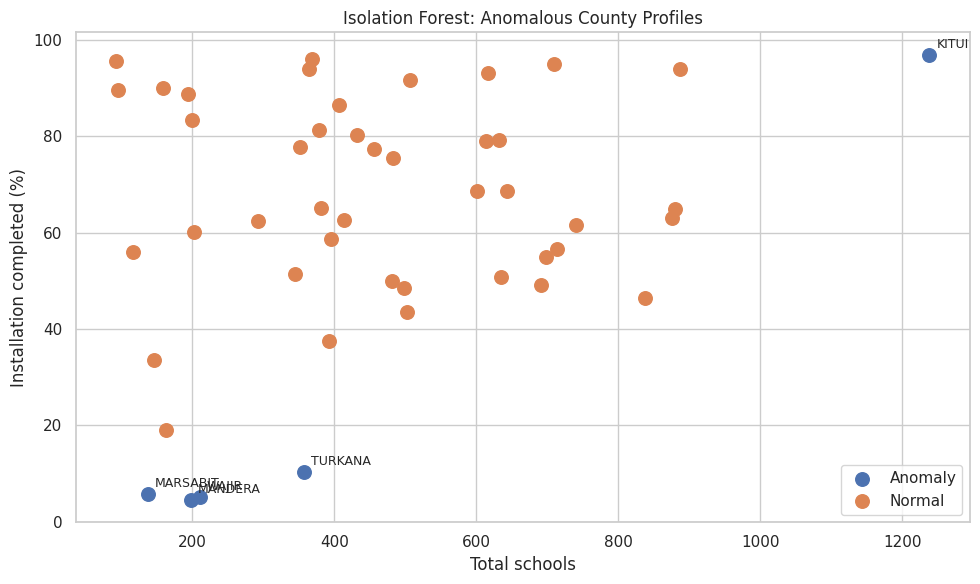

In [13]:
plt.figure(figsize=(10, 6))
for category, group in df.groupby("AnomalyLabel"):
    plt.scatter(group["TOTALSCHOOLS"], group["PercentageInstalled"], s=95, label=category)
plt.legend()
for _, record in anomalies.iterrows():
    plt.annotate(record["SNO"], (record["TOTALSCHOOLS"], record["PercentageInstalled"]),
                 xytext=(5, 5), textcoords="offset points", fontsize=9)
plt.title("Isolation Forest: Anomalous County Profiles")
plt.xlabel("Total schools")
plt.ylabel("Installation completed (%)")
plt.tight_layout()
plt.show()

Observed interpretation: In the supplied data, Isolation Forest flags KITUI, MANDERA, TURKANA, MARSABIT, WAJIR. Kitui is unusually large and has a very high installation rate. Mandera, Turkana, Marsabit and Wajir have low installation rates; some also have high LDD-per-installed-school ratios. These are mathematically unusual profiles, not proof of fraudulent or inaccurate records. The ranking may change if the chosen features or contamination setting change.

**Experiment 2 — Cluster analysis using K-Means
K-Means groups observations by distance to cluster centers. Compare k=2 through k=6 using the silhouette score, which evaluates how well-separated the clusters are; higher is better among the tested values. Use a fixed random state for reproducibility.**

,Clusters (k),Silhouette score
0,2,0.4442
1,3,0.2810
2,4,0.2978
3,5,0.2753
4,6,0.3001


Best tested k: 2


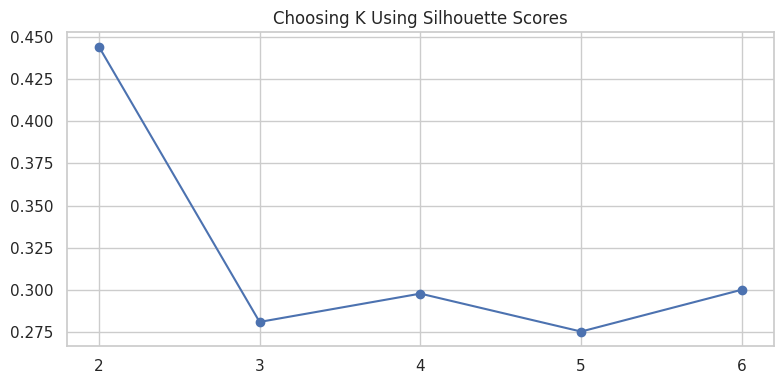

In [14]:
silhouette_scores = {}
for k in range(2, 7):
    trial_model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    labels = trial_model.fit_predict(X_scaled)
    silhouette_scores[k] = silhouette_score(X_scaled, labels)

score_table = pd.DataFrame({"Clusters (k)": list(silhouette_scores.keys()),
                            "Silhouette score": list(silhouette_scores.values())})
display(score_table.round(4))

best_k = max(silhouette_scores, key=silhouette_scores.get)
print("Best tested k:", best_k)
plt.figure(figsize=(8, 4))
plt.plot(score_table["Clusters (k)"], score_table["Silhouette score"], marker="o")
plt.xticks(range(2, 7))
plt.title("Choosing K Using Silhouette Scores")
plt.tight_layout()
plt.show()

In [15]:
kmeans = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=20)
df["Cluster"] = kmeans.fit_predict(X_scaled)

print("Counties per cluster:")
print(df["Cluster"].value_counts().sort_index())
cluster_profile = df.groupby("Cluster")[features + ["TotalSchoolsInstalled", "SchoolsPending"]].mean().round(2)
display(cluster_profile)

for cluster_id, group in df.groupby("Cluster"):
    print(f"Cluster {cluster_id} ({len(group)} counties): {', '.join(group['SNO'])}")

Counties per cluster:
Cluster
0    41
1     6
Name: count, dtype: int64


,TOTALSCHOOLS,PercentageInstalled,LDDsPerInstalledSchool,TotalSchoolsInstalled,SchoolsPending
Cluster,,,,,
0,500.37,71.36,49.04,353.27,147.10
1,202.33,13.08,80.08,24.17,178.17


Cluster 0 (41 counties): HOMA BAY, WEST POKOT, KITUI, TANA RIVER, TAITA TAVETA, UASIN GISHU, MIGORI, VIHIGA, NYAMIRA, NAROK, NANDI, MOMBASA, MAKUENI, LAMU, KISII, KISUMU, KAKAMEGA, BUNGOMA, BOMET, KILIFI, BUSIA, ElGEYO, TRANS NZOIA, KWALE, SIAYA, KERICHO, MERU, LAIKIPIA, KIRINYAGA, ISIOLO, KIAMBU, MURANG'A, NYERI, NYANDARUA, MACHAKOS, NAIROBI, NAKURU, THARAKA NITHI, BARINGO, KAJIADO, EMBU
Cluster 1 (6 counties): TURKANA, GARISSA, MANDERA, WAJIR, MARSABIT, SAMBURU


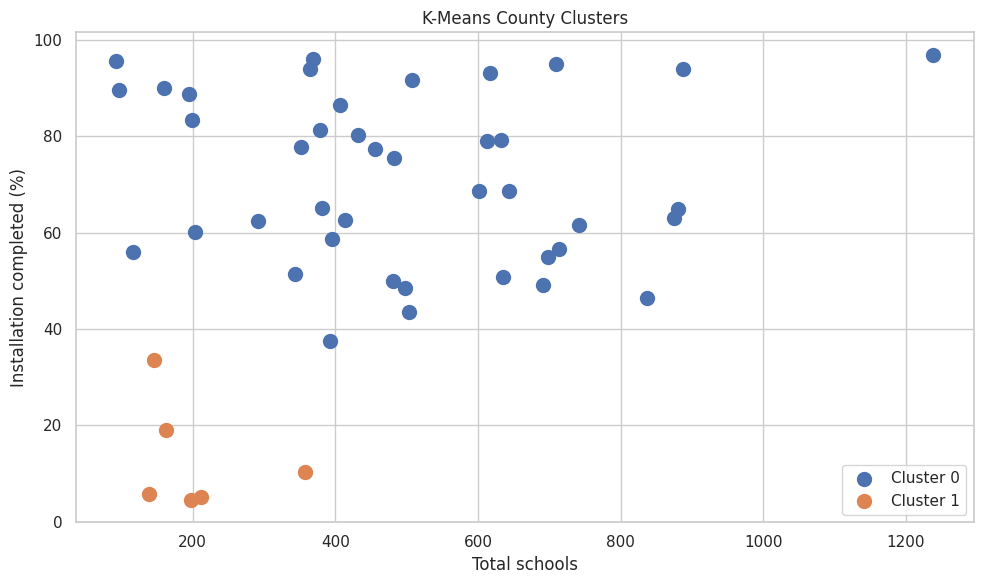

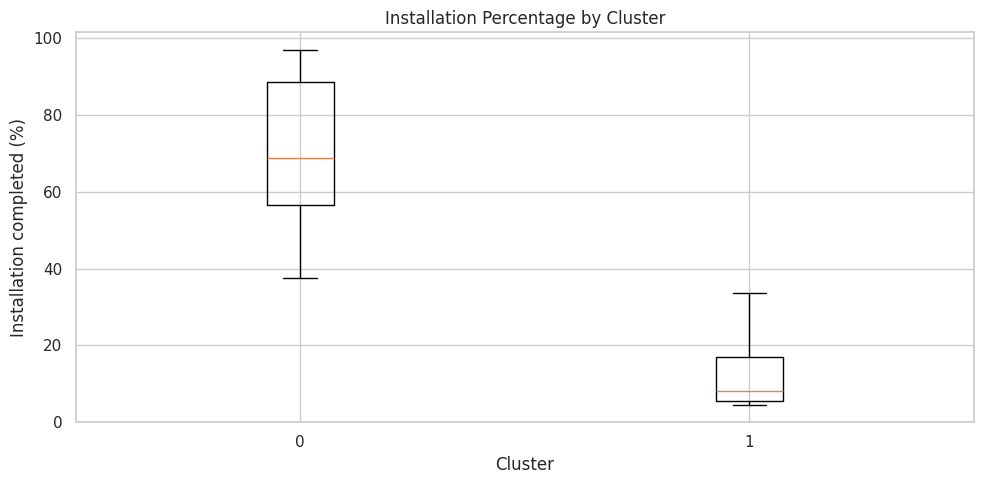

In [16]:
plt.figure(figsize=(10, 6))
for cluster_id, group in df.groupby("Cluster"):
    plt.scatter(group["TOTALSCHOOLS"], group["PercentageInstalled"], s=100, label=f"Cluster {cluster_id}")
plt.legend()
plt.title("K-Means County Clusters")
plt.xlabel("Total schools")
plt.ylabel("Installation completed (%)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.boxplot([group["PercentageInstalled"].to_numpy() for _, group in df.groupby("Cluster")],
            tick_labels=[str(i) for i in sorted(df["Cluster"].unique())])
plt.title("Installation Percentage by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Installation completed (%)")
plt.tight_layout()
plt.show()

Observed interpretation: k=2 produces the best silhouette score (0.4442) among 2–6 groups. Cluster 0 consists of 41 counties with an average completion rate of 71.36%. Cluster 1 consists of 6 counties with an average completion rate of 13.08%. Cluster 1 contains Turkana, Garissa, Mandera, Wajir, Marsabit and Samburu. Cluster numbers are arbitrary labels, not ordered rankings.

Caution: This is a small cross-sectional dataset. Results describe association and do not explain why county installation rates differ. The choice of modeling features can change cluster membership.